# Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia

Phần 2 – Bài 5a (trang 45): Làm lại bài lập trình hướng dẫn chung với nước Đức, min_sup = 5%, min_conf = 50%

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [2]:
import os
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from mlxtend.frequent_patterns import apriori, fpgrowth
from mlxtend.frequent_patterns import association_rules
pd.set_option('display.max_colwidth', 80)


def tao_luat(itemsets, n_trans, min_conf):
    """Sinh luật kết hợp (tương thích nhiều phiên bản mlxtend)."""
    try:
        return association_rules(itemsets, num_itemsets=n_trans, metric="confidence", min_threshold=min_conf)
    except TypeError:
        return association_rules(itemsets, metric="confidence", min_threshold=min_conf)


def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    if datapoint >= 1:
        return 1

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
COUNTRY = 'Germany'
MIN_SUP = 0.05    # 5%
MIN_CONF = 0.5   # 50%

# Đọc file Excel (~1-2 phút). Lần đầu đọc sẽ lưu bản cache .pkl để các câu sau đọc nhanh hơn
CACHE = DATA + 'online_retail.pkl'
if os.path.exists(CACHE):
    df = pd.read_pickle(CACHE)
else:
    df = pd.read_excel(DATA + 'Online Retail.xlsx')
    df.to_pickle(CACHE)

df['Description'] = df['Description'].str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')

df = df[~df['InvoiceNo'].str.contains('C')]

C:\Users\Admin\AppData\Local\Temp\ipykernel_27332\2282523079.py:14: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)


---
## Thực hiện yêu cầu

In [4]:
print(SV)
df['Country'].value_counts()

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


Country
United Kingdom          487622
Germany                   9042
France                    8408
EIRE                      7894
Spain                     2485
Netherlands               2363
Belgium                   2031
Switzerland               1967
Portugal                  1501
Australia                 1185
Norway                    1072
Italy                      758
Channel Islands            748
Finland                    685
Cyprus                     614
Sweden                     451
Unspecified                446
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     295
Hong Kong                  284
Singapore                  222
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         58


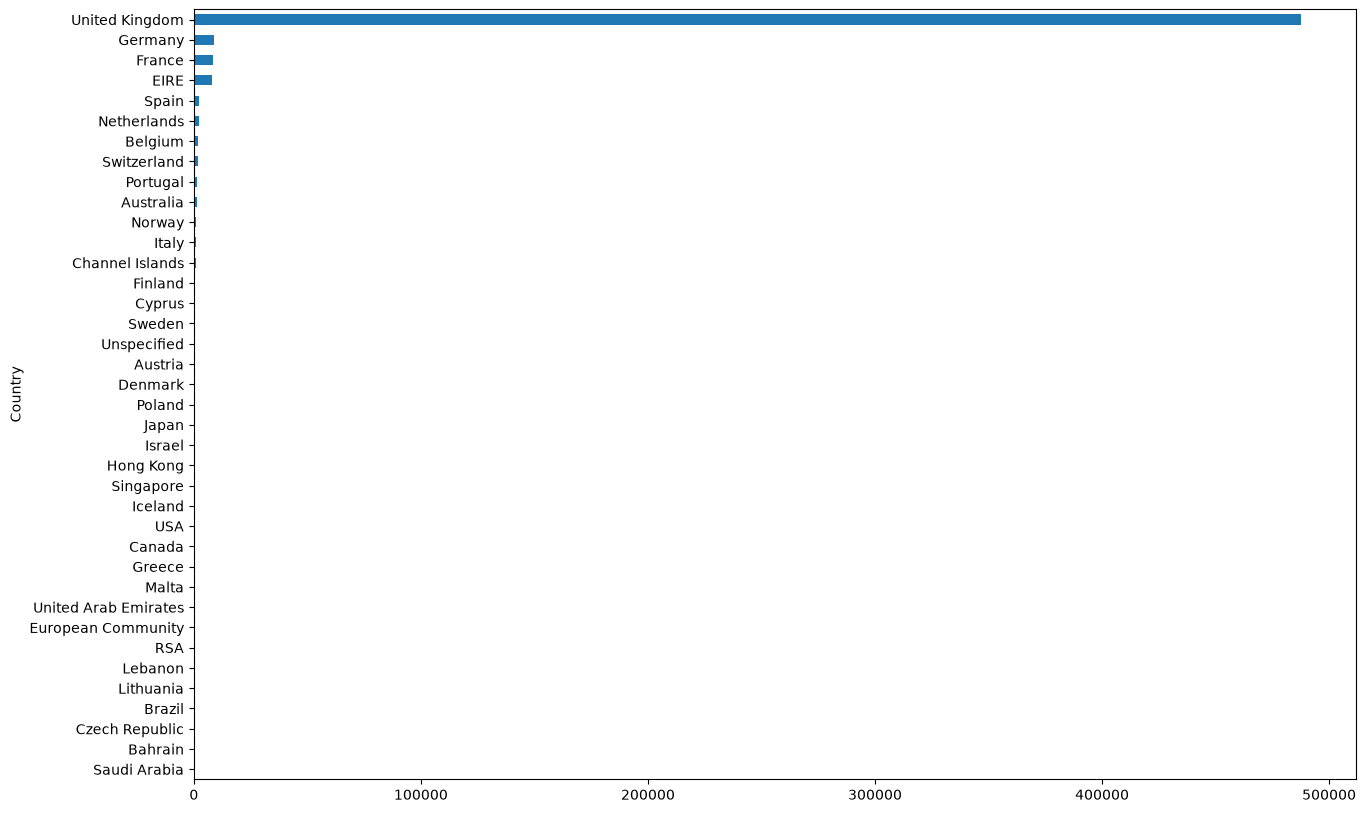

In [5]:
df['Country'].value_counts().sort_values().plot(kind='barh', figsize=(15, 10))
plt.show()